<a href="https://colab.research.google.com/github/Shreevatsa-NP/BIS/blob/main/ant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best job schedule:
['J2', 'J4', 'J1', 'J5', 'J3']
Minimum total completion time: 51

Job	Processing Time	Completion Time
J2	2		2
J4	3		5
J1	4		9
J5	5		14
J3	7		21


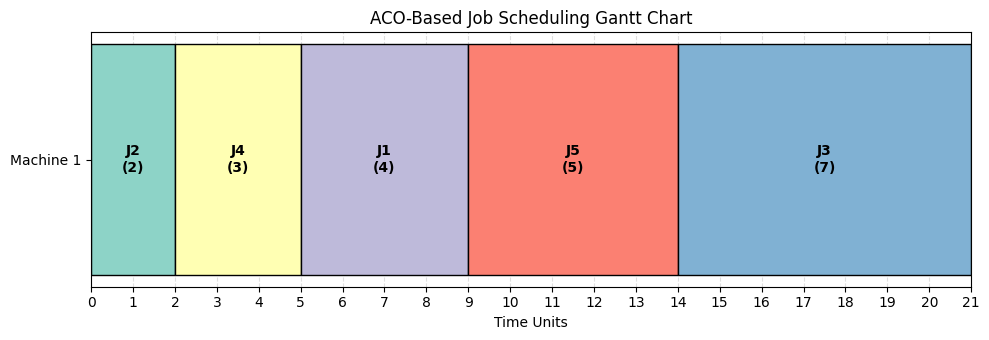

In [10]:

import random
import matplotlib.pyplot as plt


jobs = [4, 2, 7, 3, 5]
n = len(jobs)


num_ants = 10
num_iterations = 100
alpha = 1.0
beta = 2.0
evaporation = 0.5
Q = 100


pheromone = [[1.0 for _ in range(n)] for _ in range(n)]


def calculate_cost(schedule):
    """Calculate total completion time."""
    current_time = 0
    total_time = 0

    for job in schedule:
        current_time += jobs[job]
        total_time += current_time

    return total_time


def construct_solution():
    """Construct a job schedule using ACO."""
    unvisited = list(range(n))
    schedule = []
    current = 0

    while unvisited:
        weights = []

        for job in unvisited:
            heuristic = 1.0 / jobs[job]
            weight = (
                pheromone[current][job] ** alpha
                * heuristic ** beta
            )
            weights.append(weight)

        selected = random.choices(
            unvisited, weights=weights, k=1
        )[0]

        schedule.append(selected)
        unvisited.remove(selected)
        current = selected

    return schedule



best_schedule = None
best_cost = float("inf")

for iteration in range(num_iterations):
    ant_solutions = []

    for ant in range(num_ants):
        schedule = construct_solution()
        cost = calculate_cost(schedule)
        ant_solutions.append((schedule, cost))

        if cost < best_cost:
            best_schedule = schedule[:]
            best_cost = cost

    for i in range(n):
        for j in range(n):
            pheromone[i][j] *= (1 - evaporation)

    for schedule, cost in ant_solutions:
        deposit = Q / cost

        for i in range(len(schedule) - 1):
            a = schedule[i]
            b = schedule[i + 1]
            pheromone[a][b] += deposit



print("Best job schedule:")
print([f"J{job + 1}" for job in best_schedule])
print("Minimum total completion time:", best_cost)

print("\nJob\tProcessing Time\tCompletion Time")

time = 0
for job in best_schedule:
    time += jobs[job]
    print(f"J{job + 1}\t{jobs[job]}\t\t{time}")

fig, ax = plt.subplots(figsize=(10, 3.5))

colors = plt.cm.Set3.colors
start_time = 0

for i, job in enumerate(best_schedule):
    duration = jobs[job]

    ax.barh(
        0,
        duration,
        left=start_time,
        height=0.55,
        color=colors[i % len(colors)],
        edgecolor="black"
    )

    ax.text(
        start_time + duration / 2,
        0,
        f"J{job + 1}\n({duration})",
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

    start_time += duration

ax.set_title("ACO-Based Job Scheduling Gantt Chart")
ax.set_xlabel("Time Units")
ax.set_yticks([0])
ax.set_yticklabels(["Machine 1"])
ax.set_xlim(0, start_time)
ax.set_xticks(range(start_time + 1))
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()
